# EDA — Kiểm tra dữ liệu trước khi train (Tầng 0, Tầng 3, Tầng 4)

Notebook này kiểm tra chất lượng dữ liệu của cả 3 thành phần cần huấn luyện trong kiến trúc CaTE-X, **trước khi** bỏ thời gian GPU ra train:

- **Tầng 0**: dữ liệu đơn-câu (merged humarin + PADBen Task 1,2,3) — kiểm tra phân bố độ dài theo nhãn, phân bố nguồn theo split, trùng lặp nội dung giữa các tập
- **Tầng 3**: dữ liệu Triplet (Anchor, Positive, Negative) — kiểm tra similarity Positive vs Negative, độ dài câu, xem mẫu bằng mắt
- **Tầng 4**: dữ liệu Cặp-có-nhãn (sentence_1, sentence_2, label) — kiểm tra cân bằng nhãn, độ dài 2 vế, thống kê tập cross-eval PADBen (Task 4, 5)

In [17]:
# Cài đặt (bỏ qua nếu đã có sẵn trên Colab/Kaggle)
# !pip install pandas scikit-learn matplotlib scipy -q

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

SIMILARITY_SAMPLE_SIZE = 50_000  # Lấy mẫu để tính similarity cho nhanh, không cần full data

## Cấu hình đường dẫn — SỬA LẠI cho khớp với máy của bạn

In [18]:
# Tầng 0
TANG0_TRAIN = "../data/splits/tang0_train.csv"
TANG0_VAL = "../data/splits/tang0_val.csv"
TANG0_TEST = "../data/splits/tang0_test.csv"

# Tầng 3
TRIPLET_PATH = "../data/splits/triplet_data_train.csv"

# Tầng 4
PAIRWISE_PATH = "../data/splits/pairwise_labeled_train.csv"
# PADBEN_TASK4_PATH = "data/cross_eval/padben_task4_test.csv"
# PADBEN_TASK5_PATH = "data/cross_eval/padben_task5_test.csv"

OUTPUT_DIR = "../evaluation/eda_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

---
## TẦNG 0 — Kiểm tra dữ liệu đơn-câu (train / val / test)

In [19]:
df_train = pd.read_csv(TANG0_TRAIN)
df_val = pd.read_csv(TANG0_VAL)
df_test = pd.read_csv(TANG0_TEST)

for name, df in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"--- Tập {name}: {len(df):,} dòng ---")
    print("Tỷ lệ nhãn:")
    print(df["label"].value_counts(normalize=True).rename("tỷ lệ").to_string())
    if "source" in df.columns:
        print("Tỷ lệ nguồn (source):")
        print(df["source"].value_counts(normalize=True).rename("tỷ lệ").to_string())
    print()

--- Tập train: 1,827,865 dòng ---
Tỷ lệ nhãn:
label
1    0.820814
0    0.179186
Tỷ lệ nguồn (source):
source
humarin         0.962647
padben_task1    0.012483
padben_task2    0.012481
padben_task3    0.012388

--- Tập val: 391,749 dòng ---
Tỷ lệ nhãn:
label
1    0.820844
0    0.179156
Tỷ lệ nguồn (source):
source
humarin         0.962731
padben_task3    0.012707
padben_task2    0.012365
padben_task1    0.012197

--- Tập test: 391,887 dòng ---
Tỷ lệ nhãn:
label
1    0.820908
0    0.179092
Tỷ lệ nguồn (source):
source
humarin         0.962943
padben_task1    0.012427
padben_task3    0.012361
padben_task2    0.012269



### Kiểm tra 1 — Phân bố độ dài câu theo nhãn

Nếu 2 lớp chênh lệch độ dài quá lớn, model có nguy cơ học "mẹo" đếm độ dài thay vì học phong cách viết thật.

In [20]:
df_train = df_train.copy()
df_train["n_words"] = df_train["sentence"].astype(str).str.split().str.len()

print(df_train.groupby("label")["n_words"].describe().to_string())

mean_diff = (
    df_train.loc[df_train["label"] == 1, "n_words"].mean()
    - df_train.loc[df_train["label"] == 0, "n_words"].mean()
)
print(f"\nChênh lệch độ dài trung bình (label 1 - label 0): {mean_diff:+.2f} từ")
if abs(mean_diff) > 3:
    print("CẢNH BÁO: chênh lệch độ dài giữa 2 lớp khá lớn (>3 từ). "
          "Model có nguy cơ học 'mẹo' đếm độ dài thay vì học phong cách viết "
          "thật. Cân nhắc kiểm tra kỹ hoặc chuẩn hóa độ dài khi sampling.")

           count       mean       std  min   25%   50%   75%    max
label                                                              
0       327528.0  16.262439  11.37381  1.0   9.0  14.0  21.0  436.0
1      1500337.0  16.572885   9.38260  1.0  10.0  14.0  21.0  889.0

Chênh lệch độ dài trung bình (label 1 - label 0): +0.31 từ


In [30]:
thresholds = [(1, 5), (5, 100), (100, 999)]
for lo, hi in thresholds:
    mask = (df_train["n_words"] >= lo) & (df_train["n_words"] < hi)
    print(f"[{lo}–{hi}) từ: {mask.sum():,} ({mask.mean()*100:.1f}%)")


[1–5) từ: 10,101 (0.6%)
[5–100) từ: 1,817,251 (99.4%)
[100–999) từ: 513 (0.0%)


In [31]:
print(df_train.groupby(["source", "label"]).size().unstack(fill_value=0))


label              0        1
source                       
humarin       293390  1466199
padben_task1   11409    11409
padben_task2   11407    11407
padben_task3   11322    11322


In [32]:
label0 = df_pairwise[df_pairwise["label"] == 0]
same = (label0["sentence_1"].str.strip().str.lower() == 
        label0["sentence_2"].str.strip().str.lower()).sum()
print(f"Label=0 nhưng 2 câu giống nhau: {same:,}")


Label=0 nhưng 2 câu giống nhau: 0


In [33]:
for name, df in [("train", df_train), ("val", df_val), ("test", df_test)]:
    n_null = df["sentence"].isna().sum()
    n_empty = (df["sentence"].astype(str).str.strip() == "").sum()
    print(f"{name}: NaN={n_null}, rỗng={n_empty}")


train: NaN=0, rỗng=0
val: NaN=0, rỗng=0
test: NaN=0, rỗng=0


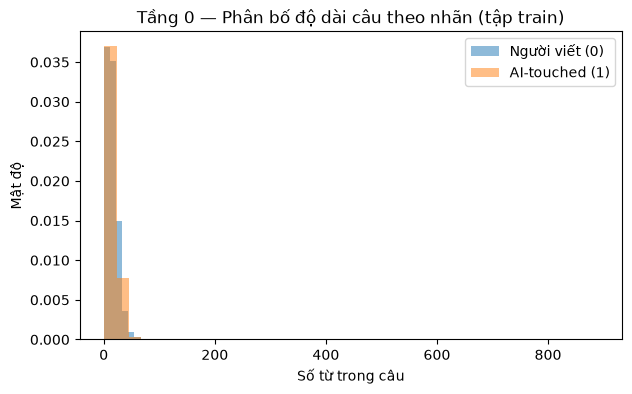

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
for label_value, color, name in [(0, "tab:blue", "Người viết (0)"),
                                  (1, "tab:orange", "AI-touched (1)")]:
    subset = df_train.loc[df_train["label"] == label_value, "n_words"]
    ax.hist(subset, bins=40, alpha=0.5, density=True, label=name, color=color)
ax.set_xlabel("Số từ trong câu")
ax.set_ylabel("Mật độ")
ax.set_title("Tầng 0 — Phân bố độ dài câu theo nhãn (tập train)")
ax.legend()
fig.savefig(os.path.join(OUTPUT_DIR, "tang0_do_dai_theo_nhan.png"), dpi=120, bbox_inches="tight")
plt.show()

### Kiểm tra 2 — Trùng lặp nội dung câu giữa các tập

Dù `group_id` đã tách đúng, 2 group khác nhau vẫn có thể vô tình chứa câu giống hệt nhau (đặc biệt câu ngắn, generic).

In [22]:
norm = lambda s: s.astype(str).str.strip().str.lower()
set_train = set(norm(df_train["sentence"]))
set_val = set(norm(df_val["sentence"]))
set_test = set(norm(df_test["sentence"]))

overlap_train_val = set_train & set_val
overlap_train_test = set_train & set_test
overlap_val_test = set_val & set_test

print(f"Trùng train-val : {len(overlap_train_val):,} câu")
print(f"Trùng train-test: {len(overlap_train_test):,} câu")
print(f"Trùng val-test  : {len(overlap_val_test):,} câu")

total_overlap = len(overlap_train_val) + len(overlap_train_test) + len(overlap_val_test)
if total_overlap > 0:
    print("CẢNH BÁO: có câu trùng nội dung giữa các tập dù khác group_id. "
          "Nếu số lượng đáng kể so với tổng số dòng, cân nhắc lọc bớt.")
else:
    print("Không phát hiện trùng lặp nội dung giữa các tập.")

Trùng train-val : 17,437 câu
Trùng train-test: 17,386 câu
Trùng val-test  : 4,110 câu
CẢNH BÁO: có câu trùng nội dung giữa các tập dù khác group_id. Nếu số lượng đáng kể so với tổng số dòng, cân nhắc lọc bớt.


---
## TẦNG 3 — Kiểm tra dữ liệu Triplet (Anchor, Positive, Negative)

In [23]:
df_triplet = pd.read_csv(TRIPLET_PATH)
print(f"Tổng số dòng: {len(df_triplet):,}")

if len(df_triplet) > SIMILARITY_SAMPLE_SIZE:
    df_triplet_sample = df_triplet.sample(n=SIMILARITY_SAMPLE_SIZE, random_state=42).reset_index(drop=True)
    print(f"Lấy mẫu {SIMILARITY_SAMPLE_SIZE:,} dòng để tính similarity cho nhanh")
else:
    df_triplet_sample = df_triplet

for col in ["anchor", "positive", "negative"]:
    lengths = df_triplet_sample[col].astype(str).str.split().str.len()
    print(f"Độ dài '{col}': trung bình={lengths.mean():.1f} từ, min={lengths.min()}, max={lengths.max()}")

Tổng số dòng: 1,466,402
Lấy mẫu 50,000 dòng để tính similarity cho nhanh
Độ dài 'anchor': trung bình=15.7 từ, min=1, max=106
Độ dài 'positive': trung bình=16.5 từ, min=1, max=84
Độ dài 'negative': trung bình=14.9 từ, min=2, max=94


### Kiểm tra — Similarity (Anchor, Positive) vs (Anchor, Negative)

Tính cosine similarity **từng cặp** (row-wise), KHÔNG tính ma trận N×N — an toàn bộ nhớ dù dataset có hàng triệu dòng.

In [24]:
def paired_cosine_similarity(vectorizer, text_a, text_b):
    vec_a = vectorizer.transform(text_a)
    vec_b = vectorizer.transform(text_b)
    # TfidfVectorizer mặc định đã chuẩn hóa L2, nên dot product từng cặp
    # hàng chính là cosine similarity
    product = vec_a.multiply(vec_b)
    return np.asarray(product.sum(axis=1)).flatten()

vectorizer = TfidfVectorizer()
all_texts = (
    df_triplet_sample["anchor"].astype(str).tolist()
    + df_triplet_sample["positive"].astype(str).tolist()
    + df_triplet_sample["negative"].astype(str).tolist()
)
vectorizer.fit(all_texts)

sim_ap = paired_cosine_similarity(vectorizer, df_triplet_sample["anchor"], df_triplet_sample["positive"])
sim_an = paired_cosine_similarity(vectorizer, df_triplet_sample["anchor"], df_triplet_sample["negative"])

print(f"Similarity (Anchor, Positive): trung bình={sim_ap.mean():.3f}, trung vị={np.median(sim_ap):.3f}")
print(f"Similarity (Anchor, Negative): trung bình={sim_an.mean():.3f}, trung vị={np.median(sim_an):.3f}")

gap = sim_ap.mean() - sim_an.mean()
print(f"Khoảng cách trung bình (AP - AN): {gap:+.3f}")
if gap < 0.1:
    print("CẢNH BÁO: khoảng cách giữa Positive và Negative khá nhỏ (<0.1). "
          "Dữ liệu có thể 'khó học' quá mức hoặc hard-negative đang chọn "
          "những câu quá giống Positive. Nên lấy mẫu kiểm tra bằng mắt.")

n_overlap = (sim_an >= sim_ap).sum()
pct_overlap = n_overlap / len(df_triplet_sample) * 100
print(f"Số dòng mà Negative >= Positive về similarity: {n_overlap:,} ({pct_overlap:.1f}%)")
if pct_overlap > 15:
    print("CẢNH BÁO: tỷ lệ Negative 'giống Anchor hơn cả Positive' khá cao (>15%). "
          "Cân nhắc giảm top_k_pool khi gọi lại build_triplet.py.")

Similarity (Anchor, Positive): trung bình=0.598, trung vị=0.625
Similarity (Anchor, Negative): trung bình=0.176, trung vị=0.162
Khoảng cách trung bình (AP - AN): +0.422
Số dòng mà Negative >= Positive về similarity: 2,660 (5.3%)


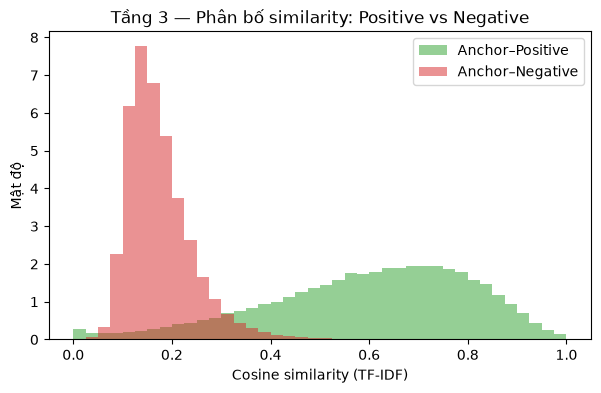

In [25]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sim_ap, bins=40, alpha=0.5, density=True, label="Anchor–Positive", color="tab:green")
ax.hist(sim_an, bins=40, alpha=0.5, density=True, label="Anchor–Negative", color="tab:red")
ax.set_xlabel("Cosine similarity (TF-IDF)")
ax.set_ylabel("Mật độ")
ax.set_title("Tầng 3 — Phân bố similarity: Positive vs Negative")
ax.legend()
fig.savefig(os.path.join(OUTPUT_DIR, "tang3_similarity_positive_vs_negative.png"), dpi=120, bbox_inches="tight")
plt.show()

### Xem vài dòng mẫu ngẫu nhiên bằng mắt

Tự đọc xem Negative có thực sự "không liên quan" không.

In [26]:
for _, row in df_triplet_sample.sample(n=min(5, len(df_triplet_sample)), random_state=1).iterrows():
    print(f"Anchor  : {row['anchor']}")
    print(f"Positive: {row['positive']}")
    print(f"Negative: {row['negative']}")
    print()

Anchor  : Milan was named as the place, here three hundred bishops assembled, most from the West, only a few from the East, in 355.
Positive: Three hundred bishops convened in Milan in 355, with most of them hailing from the West and only a handful from the East.
Negative: The events of the story take place in Maycomb, Alabama, a fictional town that is experiencing the hardships of the Great Depression, over a three-year period from 1933 to 1935.

Anchor  : Warm welcome: Mr Cameron greeted the German leader with a kiss on the steps of 10 Downing Street, ahead of a meeting expected to be dominated by the increasingly tense talks on the EU's 2014-2020 budget .
Positive: Mr Cameron gave the German leader a friendly greeting by kissing him on the steps of 10 Downing Street, ahead of a meeting that was likely to focus on the tense discussions surrounding the EU's budget for 2014-2020.
Negative: Between the German invasion of Poland on 1 September 1939 and the Anglo-French declaration of War

---
## TẦNG 4 — Kiểm tra dữ liệu Cặp-có-nhãn (sentence_1, sentence_2, label)

In [27]:
df_pairwise = pd.read_csv(PAIRWISE_PATH)
print(f"Tổng số dòng: {len(df_pairwise):,}")

print("\nTỷ lệ nhãn:")
label_ratio = df_pairwise["label"].value_counts(normalize=True)
print(label_ratio.rename("tỷ lệ").to_string())
if abs(label_ratio.get(0, 0) - label_ratio.get(1, 0)) > 0.1:
    print("CẢNH BÁO: lệch khỏi 50/50 hơn 10 điểm %, kiểm tra lại bước build_pairwise.")
else:
    print("Cân bằng tốt (~50/50).")

Tổng số dòng: 2,932,874

Tỷ lệ nhãn:
label
0    0.5
1    0.5
Cân bằng tốt (~50/50).


Độ dài sentence_1: trung bình=15.7 từ
Độ dài sentence_2: trung bình=16.5 từ
Chênh lệch trung bình: +0.8 từ


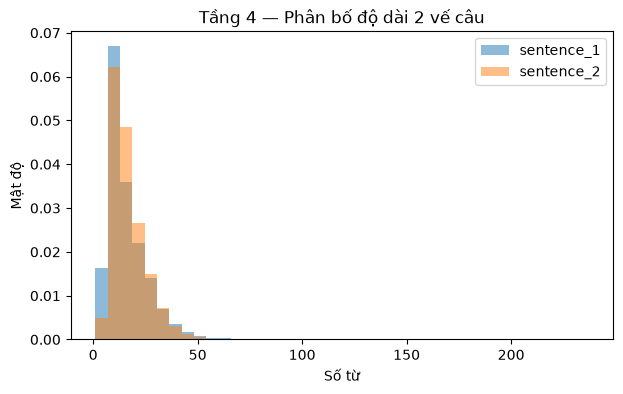

In [28]:
len_1 = df_pairwise["sentence_1"].astype(str).str.split().str.len()
len_2 = df_pairwise["sentence_2"].astype(str).str.split().str.len()
print(f"Độ dài sentence_1: trung bình={len_1.mean():.1f} từ")
print(f"Độ dài sentence_2: trung bình={len_2.mean():.1f} từ")
print(f"Chênh lệch trung bình: {(len_2.mean() - len_1.mean()):+.1f} từ")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(len_1, bins=40, alpha=0.5, density=True, label="sentence_1", color="tab:blue")
ax.hist(len_2, bins=40, alpha=0.5, density=True, label="sentence_2", color="tab:orange")
ax.set_xlabel("Số từ")
ax.set_ylabel("Mật độ")
ax.set_title("Tầng 4 — Phân bố độ dài 2 vế câu")
ax.legend()
fig.savefig(os.path.join(OUTPUT_DIR, "tang4_do_dai_2_ve.png"), dpi=120, bbox_inches="tight")
plt.show()

### Thống kê các tập cross-eval (PADBen Task 4, Task 5)

Task 4: cả 2 vế đều label=1 (đo Recall theo độ sâu paraphrase). Task 5: có cả label 0 và 1 (đo khả năng phân biệt người/AI ở paraphrase sâu).

In [29]:
# cross_eval_paths = {
#     "PADBen Task 4": PADBEN_TASK4_PATH,
#     "PADBen Task 5": PADBEN_TASK5_PATH,
# }

# for name, path in cross_eval_paths.items():
#     if not os.path.exists(path):
#         print(f"[{name}] KHÔNG tìm thấy file: {path}")
#         continue
#     df_ce = pd.read_csv(path)
#     print(f"[{name}] {len(df_ce):,} dòng, các cột: {list(df_ce.columns)}")
#     if len(df_ce) < 200:
#         print(f"  CẢNH BÁO: chỉ có {len(df_ce)} mẫu — khá ít để kết luận có ý nghĩa "
#               f"thống kê. Kết quả trên tập này nên coi là tham khảo.")
#     if "label" in df_ce.columns:
#         print("  Tỷ lệ nhãn:")
#         print("  " + df_ce["label"].value_counts(normalize=True).to_string().replace("\n", "\n  "))
#     if "paraphrase_round" in df_ce.columns:
#         print("  Phân bố paraphrase_round:")
#         print("  " + df_ce["paraphrase_round"].value_counts().to_string().replace("\n", "\n  "))
#     print()

---
## Tổng kết

Sau khi chạy xong, kiểm tra lại các dòng **"CẢNH BÁO"** ở trên:
- Nếu **không có cảnh báo nào** → yên tâm bắt đầu train
- Nếu **có cảnh báo** → đọc kỹ nội dung gợi ý đi kèm, cân nhắc quay lại bước xử lý dữ liệu trước khi train, tránh tốn thời gian GPU cho dữ liệu có vấn đề